## Author: Gabriel Vance
## Class: DSC540 - Data Preparation
## Professor: Catherine Williams
## Date: July 5, 2025

# Purpose: This notebook performs various tasks labeled "Exercises" for Week 7/8 of the class. Data must be present within the folder that this notebook is run in.
# This week focuses on Advanced Data Gathering & Visualization

## The Data Wrangling Workshop
## Exercise 7.01: Using the Requests Library to Get a Response from the Wikipedia Home Page

### Exercise 7.01
#### Step 1 - Open a new Jupyter Notebook and import the requests library

In [145]:
import requests

### Exercise 7.01
#### Step 2 - Assign the home page URL to a variable, wiki_home

In [146]:
wiki_home = "https://en.wikipedia.org/wiki/Main_Page"

### Exercise 7.01
#### Step 3 - Assign the home page URL to a variable, wiki_home


In [147]:
response = requests.get(wiki_home)
response

<Response [200]>

### Exercise 7.01
#### Step 4. To find out more about the response object, enter the following code:

In [148]:
type(response)

requests.models.Response

## The Data Wrangling Workshop
## Exercise 7.02: Checking the Status of the Web Request

### Exercise 7.02
#### Step 1. Open a new Jupyter notebook and create a status_check function

In [149]:
def check_status(response):
    """
    Check the status of the response object.
    
    Parameters:
    response (requests.Response): The response object to check.
    
    Returns:
    str: A message indicating the status of the response.
    """
    if response.status_code == 200:
        print("Request was successful!")
        return 1
    else:
        print("Request failed!")
        return -1

### Exercise 7.02
#### Step 2. Import the requests library:

In [150]:
import requests

### Exercise 7.02
#### Step 3. Assign the home page URL to a variable, wiki_home:

In [151]:
wiki_home = "https://en.wikipedia.org/wiki/Main_Page"

### Exercise 7.02
#### Step 4. Use the get method from the requests library to get a response from this page:

In [152]:
response = requests.get(wiki_home)

### Exercise 7.02
#### Step 5. Pass the response object to the status_check function to examine the status of the response:

In [153]:
check_status(response)

Request was successful!


1

## Exercise 7.03: Connect to an API of your choice and do a simple data pull - you can use any API - except the API you have selected for your project.

In [154]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

# Config
COINGECKO_BASE_URL = "https://api.coingecko.com/api/v3"
VS_CURRENCY = "usd"
DAYS = "30"
PER_PAGE = 10
EXCLUDED_SYMBOLS = {"usdt"}

# --- Fetch Bitcoin Price Data ---
btc_url = f"{COINGECKO_BASE_URL}/coins/bitcoin/market_chart"
btc_params = {"vs_currency": VS_CURRENCY, "days": DAYS}
btc_data = requests.get(btc_url, params=btc_params).json()
btc_df = pd.DataFrame(btc_data["prices"], columns=["timestamp", "price"])
btc_df["date"] = pd.to_datetime(btc_df["timestamp"], unit="ms")
print("Bitcoin Data:")
print(btc_df.head())

Bitcoin Data:
       timestamp          price                    date
0  1750960985492  107269.669227 2025-06-26 18:03:05.492
1  1750964619632  107400.960104 2025-06-26 19:03:39.632
2  1750968228321  107572.246205 2025-06-26 20:03:48.321
3  1750971710585  107791.997285 2025-06-26 21:01:50.585
4  1750975425734  107038.576091 2025-06-26 22:03:45.734


## Exercise 7.04: Using one of the datasets provided in Weeks 5 & 6, or a dataset of your own, choose 3 of the following visualizations to complete. You must submit via PDF along with your code. You are free to use Matplotlib, Seaborn or another package if you prefer.

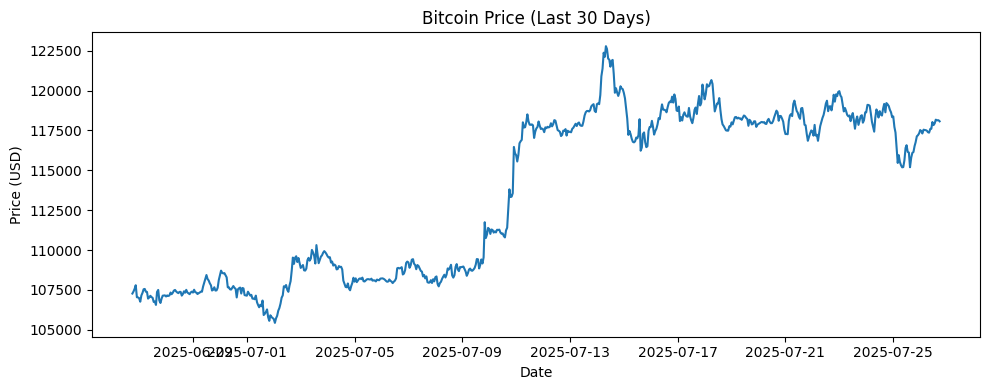

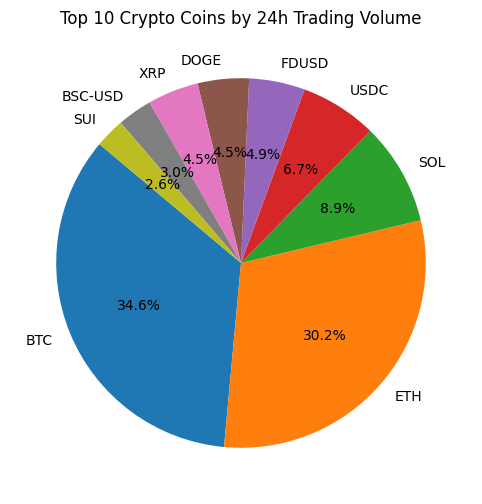

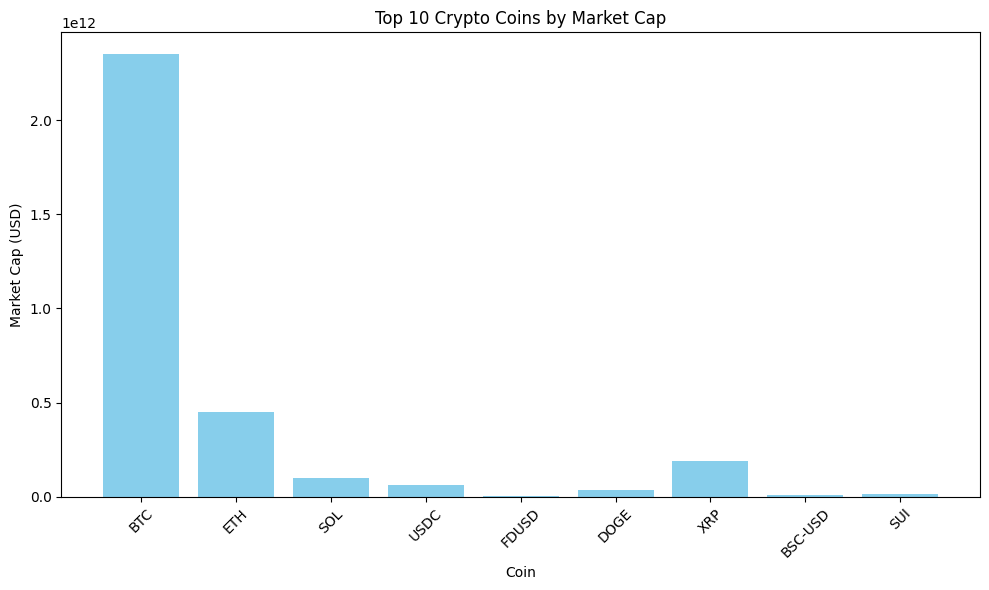

In [ ]:
# I attached the output of this code to a PDF. For my data source, I used the CoinGecko API to fetch Bitcoin price data and top coins by volume.

# --- Plot Bitcoin Price ---
plt.figure(figsize=(10, 4))
plt.plot(btc_df["date"], btc_df["price"], color="orange", linewidth=2)
plt.title("Bitcoin Price (Last 30 Days)")
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.tight_layout()
plt.show()

# --- Fetch Top Coins by Volume (excluding USDT) ---
top_url = f"{COINGECKO_BASE_URL}/coins/markets"
top_params = {
    "vs_currency": VS_CURRENCY,
    "order": "volume_desc",
    "per_page": PER_PAGE * 2,
    "page": 1
}
top_data = requests.get(top_url, params=top_params).json()
top_coins = [coin for coin in top_data if coin["symbol"].lower() not in EXCLUDED_SYMBOLS][:PER_PAGE]

symbols = [coin["symbol"].upper() for coin in top_coins]
volumes = [coin["total_volume"] for coin in top_coins]
market_caps = [coin["market_cap"] for coin in top_coins]

# --- Pie Chart: Volume Distribution ---
plt.figure(figsize=(8, 6))
plt.pie(volumes, labels=symbols, autopct="%1.1f%%", startangle=140)
plt.title("Top 10 Crypto Coins by 24h Trading Volume (Excl. USDT)")
plt.tight_layout()
plt.show()

# --- Bar Chart: Market Cap ---
plt.figure(figsize=(10, 6))
plt.bar(symbols, market_caps, color="skyblue")
plt.title("Top 10 Crypto Coins by Market Cap (Excl. USDT)")
plt.xlabel("Coin")
plt.ylabel("Market Cap (USD)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
